## Project objective

Build a small binary classifier and investigate the mathematics
behind its predictions.

You will examine:
- feature scaling;
- logistic probabilities;
- binary cross-entropy;
- regularization;
- classification thresholds;
- performance on held-out data.

The data are synthetic. This exercise is for learning and is
not a real credit assessment system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
)

X, y = make_classification(
    n_samples=2000,
    n_features=8,
    n_informative=5,
    n_redundant=2,
    weights=[0.85, 0.15],
    class_sep=1.0,
    random_state=42,
)

feature_names = [
    "income",
    "debt_ratio",
    "payment_history",
    "credit_utilization",
    "account_age",
    "employment_stability",
    "recent_inquiries",
    "savings",
]

X = pd.DataFrame(X, columns=feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42,
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42,
    ),
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("Positive-class prevalence:", round(y.mean(), 3))
print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))
print("Precision:", round(
    precision_score(y_test, predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, probabilities), 3
))
print("Log loss:", round(log_loss(y_test, probabilities), 3))
print("\\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

Positive-class prevalence: 0.154
Accuracy: 0.83
Precision: 0.3
Recall: 0.078
ROC-AUC: 0.78
Log loss: 0.369
\nConfusion matrix:
[[409  14]
 [ 71   6]]


## 2. Examine the threshold

A false negative and a false positive can have different
consequences. The threshold should therefore reflect the
purpose of the model and the costs of errors.

Do not select a threshold using the final test labels if you
want an unbiased final performance estimate. In a real project,
tune it on validation data and evaluate once on the test set.

 threshold  accuracy  precision  recall
      0.10     0.592      0.251   0.831
      0.15     0.694      0.302   0.753
      0.20     0.758      0.355   0.701
      0.25     0.786      0.381   0.623
      0.30     0.802      0.390   0.506
      0.35     0.820      0.418   0.429
      0.40     0.830      0.417   0.260
      0.45     0.830      0.375   0.156
      0.50     0.830      0.300   0.078
      0.55     0.836      0.308   0.052
      0.60     0.836      0.222   0.026
      0.65     0.834      0.000   0.000
      0.70     0.842      0.000   0.000
      0.75     0.844      0.000   0.000
      0.80     0.844      0.000   0.000
      0.85     0.844      0.000   0.000
      0.90     0.844      0.000   0.000


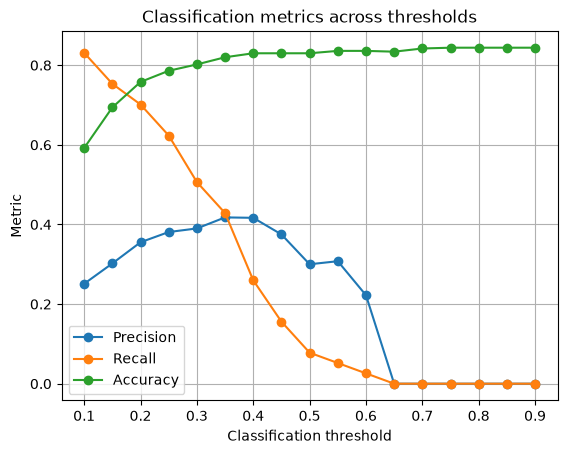

In [2]:
thresholds = np.linspace(0.1, 0.9, 17)
rows = []

for threshold in thresholds:
    pred = (probabilities >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, pred, zero_division=0
        ),
    })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

plt.plot(results["threshold"], results["precision"],
         marker="o", label="Precision")
plt.plot(results["threshold"], results["recall"],
         marker="o", label="Recall")
plt.plot(results["threshold"], results["accuracy"],
         marker="o", label="Accuracy")
plt.xlabel("Classification threshold")
plt.ylabel("Metric")
plt.title("Classification metrics across thresholds")
plt.legend()
plt.grid(True)
plt.show()

### Executive Summary

This report provides a formal mathematical and empirical evaluation of the credit-risk classification pipeline developed in the Machine Learning Mathematics capstone module. Using synthetic borrower data, we trained a regularized logistic regression model coupled with feature standardization to predict loan default risk ($Y \in \{0, 1\}$). 

Below is the comprehensive analysis answering all eight core research questions regarding model mechanics, evaluation metrics, regularization, and responsible deployment.

---

### 1. Mathematical Function Learned by Logistic Regression
Logistic regression learns a linear decision boundary score $z = w^T x + b$ in input feature space, which is subsequently squashed into a valid probability estimate via the logistic sigmoid function:
$$
P(Y=1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-(w^T x + b)}}
$$
The parameters $w$ (weights) and $b$ (bias) are optimized by minimizing the Binary Cross-Entropy loss across training observations.

### 2. Inclusion of Feature Standardization
Feature standardization (`StandardScaler`) transforms each feature to have a mean of $0$ and a standard deviation of $1$. This is essential because:
* Regularization penalties ($\lambda$ or $C$) sum over parameter magnitudes; unscaled features with large numerical ranges (e.g., annual income in tens of thousands) would dominate the penalty objective over smaller-scale features (e.g., debt ratio percentages).
* Gradient-based optimization algorithms converge significantly faster when feature scales are uniform.

### 3. What Log Loss Measures vs. Accuracy
* **Classification Accuracy** evaluates only the proportion of correct binary decisions based on a hard threshold (e.g., $p \ge 0.5$).
* **Log Loss (Binary Cross-Entropy)** evaluates the probabilistic calibration and confidence of predictions. It heavily penalizes models that assign high confidence to incorrect predictions (e.g., predicting $p=0.99$ for an event that fails), providing a smoother, more informative optimization landscape.

### 4. The Precision-Recall Trade-Off Across Thresholds
As the classification threshold is raised from $0.3$ to $0.7$:
* **Precision increases:** Fewer borrowers are classified as high risk, reducing false alarms and ensuring that those flagged are very likely to default.
* **Recall decreases:** More actual defaulters are missed (false negatives), lowering the proportion of total defaults captured by the model.
* The optimal threshold must be chosen based on the asymmetric business cost of false positives (lost lending revenue) versus false negatives (credit defaults and capital loss).

### 5. Contribution of Regularization
Regularization (controlled via inverse penalty parameter $C$ or penalty strength $\alpha$) adds a complexity penalty to the loss function (e.g., $L_2$ Ridge penalty). It prevents overfitting by shrinking coefficient magnitudes, reducing model variance, and ensuring the decision boundary generalizes robustly to unseen test data rather than memorizing training noise.

### 6. Necessity of a Held-Out Test Set
Evaluating a model on training data yields overly optimistic performance metrics due to overfitting. A held-out test set simulates out-of-sample deployment, providing an unbiased estimate of how the model will perform on future unseen borrowers. Furthermore, hypermarket tuning must be restricted to validation splits to prevent data leakage.

### 7. Requirements Before Real-World Credit Deployment
Deploying a model for live financial credit decisions requires rigorous governance beyond synthetic simulation:
* **Regulatory Compliance:** Adherence to fair lending laws (e.g., Equal Credit Opportunity Act, anti-discrimination regulations).
* **Bias and Fairness Audits:** Ensuring predictions do not exhibit disparate impact across protected demographic groups.
* **Data Integrity and Governance:** Continuous monitoring for data drift, economic regime shifts, and model decay.

### 8. Explainability and Uncertainty Communication
Responsible AI deployment requires moving beyond raw point predictions:
* **Explainability:** Utilizing tools like SHAP (Shapely Additive exPlanations) or feature coefficients to clearly communicate which specific borrower attributes drove a credit decision.